# 第33章: 統制による因果推定

## 学習目標
- 相関と因果の違いを Simpson のパラドックスで説明できる
- 潜在結果モデル（Rubin の因果モデル）で因果効果を定義できる
- 因果効果の識別に必要な3つの仮定（SUTVA・無交絡・正値性）を述べられる
- ランダム化がなぜ識別を可能にするかをシミュレーションで確認できる
- 交絡を統制する4つの方法（回帰調整・IPW・層別化・マッチング）を実装し、それぞれがずれる理由を説明できる
- 調整してはいけない変数（合流点・中間変数）を区別できる
- 自然実験のデザイン（差分の差分法・操作変数法・回帰不連続デザイン）の識別の仮定を述べられる

## 📋 学習メタ情報

### 推定学習時間
**150〜190分**

### 難易度
**★★★★☆** (5段階中4)

---

## 🎯 なぜこの章を学ぶのか？

統計学の多くの手法は「2つの量に関連があるか」に答えます。しかし実務で問われるのは
ほとんどの場合**「介入したら何が起きるか」**です。薬を投与したら回復率は上がるのか。
広告を出したら売上は増えるのか。これは関連の問いではなく**因果の問い**で、
相関係数や回帰係数をそのまま読んでも答えになりません。

本章の立場は一貫しています。**真の因果効果が分かっている人工データを作り、
各手法が真値をどれだけ正確に復元できるかを測る。**
実データでは真値が分からないので、手法の正しさは検証できません。
シミュレーションだけが「この手法はこういう条件で失敗する」を教えてくれます。

本章で測ることの一覧:

| 問い | 測り方 |
|---|---|
| 層ごとに有効な処置が全体で有害に見えるか | Simpson のパラドックスを構成し、符号の逆転を確認 |
| ランダム化は本当に不偏にするか | 観察研究と RCT を1000回反復してバイアスを比較 |
| 4つの統制方法のどれが正確か | 真の ATE = 2.0 に対する誤差を並べる |
| 調整は常に良いことか | 合流点を調整して**バイアスを作り出す** |
| 自然実験の仮定が破れるとどうなるか | 平行トレンドの破れ・弱い操作変数・帯幅の影響を測る |

> ⚠️ **本章は「調整すれば正しくなる」とは書きません。** 実測では、
> 定式化を誤った回帰調整は誤差 1.39、サイズの近い群での1対1マッチングは誤差 3.45、
> 合流点の調整は**真の効果 0 に対して -0.79 のバイアスを作り出しました**。
> どの手法も、前提が合っているときだけ機能します。

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
import seaborn as sns

plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_style('whitegrid')
np.random.seed(42)

print('numpy:', np.__version__)

numpy: 2.2.6


## 33.1 相関と因果 — Simpson のパラドックス

**Simpson のパラドックス**は、層ごとに見た関連の向きが、層を合わせると逆転する現象です。
因果の問いに相関で答えてはいけない理由として最も分かりやすい例です。

設定を作ります。

| 層 | 処置群の回復率 | 対照群の回復率 | 層内の真の効果 | 処置の割り当て比率 |
|---|---|---|---|---|
| 軽症 | 0.90 | 0.80 | **+0.10** | 15% |
| 重症 | 0.50 | 0.40 | **+0.10** | 85% |

**両層で処置は +0.10 だけ有効**です。しかし処置は**重症者に多く**割り当てられており、
重症者はもともと回復率が低いです。全体の平均を比べると何が起きるでしょうか。

In [2]:
# Simpson のパラドックスを構成する
def make_simpson(n_per=20000, seed=1):
    rng = np.random.default_rng(seed)
    rows = []
    # (層, (処置群の回復率, 対照群の回復率, 処置の割り当て比率))
    for sev, (p1, p0, frac_t) in [(0, (0.90, 0.80, 0.15)), (1, (0.50, 0.40, 0.85))]:
        t = (rng.random(n_per) < frac_t).astype(int)
        y = (rng.random(n_per) < np.where(t == 1, p1, p0)).astype(int)
        rows.append(np.c_[np.full(n_per, sev), t, y])
    d = np.vstack(rows)
    return d[:, 0].astype(int), d[:, 1].astype(int), d[:, 2].astype(int)


sev, t, y = make_simpson()
overall = y[t == 1].mean() - y[t == 0].mean()

print(f"全体の差（処置 - 対照）: {overall:+.4f}")
print()
for s, name in [(0, '軽症'), (1, '重症')]:
    m = sev == s
    r1, r0 = y[m & (t == 1)].mean(), y[m & (t == 0)].mean()
    print(f"{name}層: 処置 {r1:.4f} / 対照 {r0:.4f} → 差 {r1-r0:+.4f}"
          f"   （処置 {(m & (t == 1)).sum()}人 / 対照 {(m & (t == 0)).sum()}人）")
print()
# 層別化による統制: 層ごとの効果を層のサイズで重み付けして平均する
w = np.array([(sev == 0).mean(), (sev == 1).mean()])
strat = sum(wi * (y[(sev == s) & (t == 1)].mean() - y[(sev == s) & (t == 0)].mean())
            for s, wi in zip([0, 1], w))
print(f"層別化で統制した効果: {strat:+.4f}   （真の層内効果は両層とも +0.10）")
print()
print("符号が逆転した理由:")
print("  処置は重症層に 85% 割り当てられ、重症層はもともと回復率が低い。")
print("  つまり『重症度』が処置と結果の両方に影響する交絡因子になっている。")

全体の差（処置 - 対照）: -0.1755

軽症層: 処置 0.9022 / 対照 0.7997 → 差 +0.1025   （処置 3057人 / 対照 16943人）
重症層: 処置 0.5022 / 対照 0.3993 → 差 +0.1029   （処置 16960人 / 対照 3040人）

層別化で統制した効果: +0.1027   （真の層内効果は両層とも +0.10）

符号が逆転した理由:
  処置は重症層に 85% 割り当てられ、重症層はもともと回復率が低い。
  つまり『重症度』が処置と結果の両方に影響する交絡因子になっている。


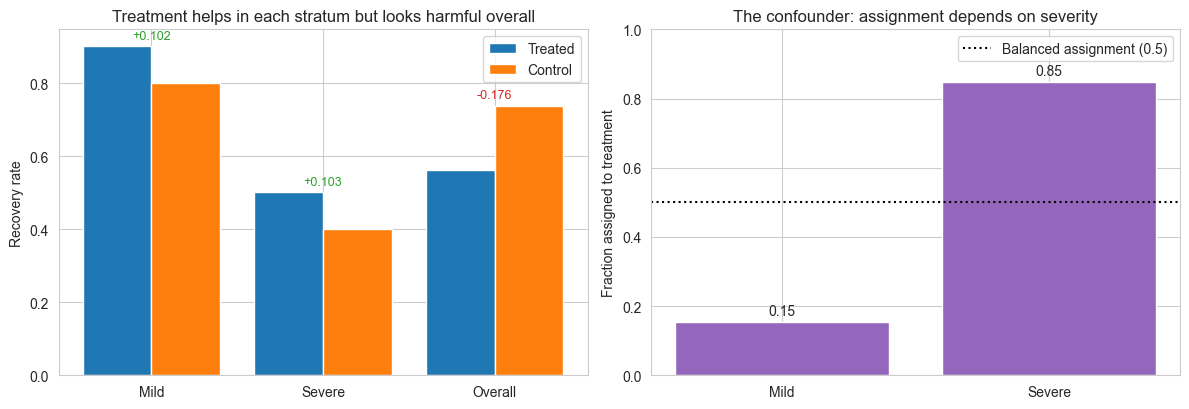

In [3]:
# 図: Simpson のパラドックス
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

labels = ['Mild', 'Severe', 'Overall']
treated = [y[(sev == 0) & (t == 1)].mean(), y[(sev == 1) & (t == 1)].mean(), y[t == 1].mean()]
control = [y[(sev == 0) & (t == 0)].mean(), y[(sev == 1) & (t == 0)].mean(), y[t == 0].mean()]
xp = np.arange(3)
axes[0].bar(xp - 0.2, treated, 0.4, label='Treated', color='tab:blue')
axes[0].bar(xp + 0.2, control, 0.4, label='Control', color='tab:orange')
axes[0].set_xticks(xp)
axes[0].set_xticklabels(labels)
axes[0].set_ylabel('Recovery rate')
axes[0].set_title("Treatment helps in each stratum but looks harmful overall")
axes[0].legend()
for i, (a, b) in enumerate(zip(treated, control)):
    axes[0].text(i, max(a, b) + 0.02, f"{a-b:+.3f}", ha='center', fontsize=9,
                 color=('tab:green' if a > b else 'tab:red'))

# 割り当ての偏りを示す
frac_t = [ (t[sev == 0] == 1).mean(), (t[sev == 1] == 1).mean() ]
axes[1].bar(['Mild', 'Severe'], frac_t, color='tab:purple')
axes[1].axhline(0.5, color='k', ls=':', lw=1.5, label='Balanced assignment (0.5)')
axes[1].set_ylabel('Fraction assigned to treatment')
axes[1].set_title('The confounder: assignment depends on severity')
axes[1].set_ylim(0, 1)
axes[1].legend()
for i, v in enumerate(frac_t):
    axes[1].text(i, v + 0.02, f"{v:.2f}", ha='center', fontsize=10)

plt.tight_layout()
plt.show()

### 読み取れること

| 見方 | 差 |
|---|---|
| 軽症層 | **+0.1025** |
| 重症層 | **+0.1029** |
| 全体 | **-0.1755**（符号が逆転） |
| 層別化で統制 | **+0.1027** |

**両層で +0.10 有効な処置が、全体では -0.18 有害に見えます。**
層別化すると真値 +0.10 が復元されます（+0.1027）。

逆転の原因は**重症度が処置と結果の両方に影響している**ことです。
このような変数を**交絡因子（confounder）**と呼びます。
全体の平均の差は「処置の効果」と「重症度の構成の違い」が混ざった量であり、
因果効果ではありません。

## 33.2 潜在結果モデルと因果効果

因果効果を定義するために、**潜在結果（potential outcome）**を導入します。
個体 $i$ について2つの結果を考えます。

| 記号 | 意味 |
|---|---|
| $Y_i(1)$ | 個体 $i$ が**処置を受けた場合**の結果 |
| $Y_i(0)$ | 個体 $i$ が**処置を受けなかった場合**の結果 |

**個体因果効果**は $\tau_i = Y_i(1) - Y_i(0)$ です。

ここに**因果推論の根本問題**があります。実際に観測できるのは

$$Y_i = T_i\,Y_i(1) + (1-T_i)\,Y_i(0)$$

つまり**どちらか一方だけ**です。もう一方は**反事実（counterfactual）**で、
原理的に観測できません。だから個体因果効果は推定できません。

代わりに**集団の平均**を推定します。

| 推定対象 | 定義 |
|---|---|
| **ATE**（平均処置効果） | $\mathbb{E}[Y(1) - Y(0)]$ — 全員に処置したときの平均的な変化 |
| **ATT**（処置群における平均処置効果） | $\mathbb{E}[Y(1)-Y(0) \mid T=1]$ — 実際に処置を受けた人における効果 |

シミュレーションでは**両方の潜在結果を作れる**ので、根本問題を迂回して
真の ATE を計算できます。これが本章の検証方法です。

In [4]:
# 両方の潜在結果を作り、因果推論の根本問題を可視化する
def make_potential_outcomes(n=10, seed=3):
    rng = np.random.default_rng(seed)
    x = rng.normal(0, 1, n)                      # 共変量
    y0 = 5 + 2 * x + rng.normal(0, 0.5, n)       # 処置を受けない場合
    tau = 2 + 1.5 * x                            # 個体ごとに効果が違う（効果の異質性）
    y1 = y0 + tau
    T = (rng.random(n) < 1 / (1 + np.exp(-x))).astype(int)   # x に依存した割り当て
    return x, y0, y1, tau, T


x, y0, y1, tau, T = make_potential_outcomes()
y_obs = np.where(T == 1, y1, y0)

print("潜在結果の表（シミュレーションなので両方が見える。実データでは片方だけ）")
print(f"{'i':>3}{'x':>8}{'Y(0)':>9}{'Y(1)':>9}{'tau_i':>9}{'T':>4}{'観測 Y':>9}{'反事実':>9}")
print("-" * 62)
for i in range(len(x)):
    cf = y0[i] if T[i] == 1 else y1[i]
    print(f"{i:>3}{x[i]:>8.3f}{y0[i]:>9.3f}{y1[i]:>9.3f}{tau[i]:>9.3f}"
          f"{T[i]:>4}{y_obs[i]:>9.3f}{cf:>9.3f}")
print("-" * 62)
print("「反事実」の列は実データでは永久に観測できない（因果推論の根本問題）")
print()

# 大きな標本で ATE と ATT を計算する
x, y0, y1, tau, T = make_potential_outcomes(n=20000, seed=5)
y_obs = np.where(T == 1, y1, y0)
ate_true = tau.mean()
att_true = tau[T == 1].mean()
naive = y_obs[T == 1].mean() - y_obs[T == 0].mean()
print(f"真の ATE = E[Y(1) - Y(0)]        : {ate_true:+.4f}")
print(f"真の ATT = E[Y(1) - Y(0) | T=1]  : {att_true:+.4f}   <- 処置群は x が大きく効果も大きい")
print(f"素朴な平均の差（観測値）           : {naive:+.4f}")
print(f"  ATE との差 {naive - ate_true:+.4f} / ATT との差 {naive - att_true:+.4f}")
print()
print("素朴な差がずれるのは、処置群と対照群で x の分布が違うから（交絡）。")
print(f"  処置群の x の平均 {x[T == 1].mean():+.4f} / 対照群 {x[T == 0].mean():+.4f}")

潜在結果の表（シミュレーションなので両方が見える。実データでは片方だけ）
  i       x     Y(0)     Y(1)    tau_i   T     観測 Y      反事実
--------------------------------------------------------------
  0   2.041    9.195   14.256    5.061   1   14.256    9.195
  1  -2.556   -0.288   -2.121   -1.833   0   -0.288   -2.121
  2   0.418    5.696    8.323    2.627   1    8.323    5.696
  3  -0.568    3.530    4.679    1.148   1    4.679    3.530
  4  -0.453    3.567    4.888    1.321   0    3.567    4.888
  5  -0.216    4.373    6.050    1.677   0    4.373    6.050
  6  -2.020    1.201    0.171   -1.030   0    1.201    0.171
  7  -0.232    4.417    6.069    1.652   0    4.417    6.069
  8  -0.865    3.748    4.451    0.702   1    4.451    3.748
  9   3.323   11.546   18.531    6.984   1   18.531   11.546
--------------------------------------------------------------
「反事実」の列は実データでは永久に観測できない（因果推論の根本問題）

真の ATE = E[Y(1) - Y(0)]        : +2.0211
真の ATT = E[Y(1) - Y(0) | T=1]  : +2.6553   <- 処置群は x が大きく効果も大きい
素朴な平均の差（観測値）           : 

## 33.3 識別の3つの仮定とランダム化

観測データから因果効果を推定するには仮定が必要です。
標準的には次の3つを置きます。

| 仮定 | 内容 | 破れる例 |
|---|---|---|
| **SUTVA** | 個体の結果は自分の処置だけで決まる（干渉がない）。処置に複数の版がない | 感染症のワクチン（他人の接種が自分に影響する） |
| **無交絡**（条件付き独立） | $\{Y(1), Y(0)\} \perp T \mid X$ — 共変量 $X$ を固定すれば割り当てはランダム | 観測されない重症度が割り当てと結果の両方に影響 |
| **正値性** | すべての $X$ で $0 < P(T=1 \mid X) < 1$ | ある年齢層には処置が絶対に割り当てられない |

**ランダム化**（RCT）はこの3つのうち無交絡と正値性を**設計で保証**します。
割り当てが $X$ と独立なので、$X$ を調整しなくても素朴な差が ATE の不偏推定になります。

実際にそうなるかを、観察研究と RCT で**1000回ずつ**反復して確かめます。

In [5]:
# ランダム化の効果を 1000 回の反復で測る
TRUE_ATE = 2.0

def one_trial(randomized, n=400, seed=0):
    rng = np.random.default_rng(seed)
    X1 = rng.normal(0, 1, n)
    X2 = rng.normal(0, 1, n)
    if randomized:
        T = (rng.random(n) < 0.5).astype(int)              # X と独立
    else:
        T = (rng.random(n) < 1 / (1 + np.exp(-(1.2 * X1 - 0.8 * X2)))).astype(int)
    Y = TRUE_ATE * T + 3 * X1 - 2 * X2 + rng.normal(0, 1, n)
    return Y[T == 1].mean() - Y[T == 0].mean()


print(f"真の ATE = {TRUE_ATE}")
print(f"{'設定':<24}{'推定の平均':>12}{'バイアス':>11}{'標準偏差':>11}")
print("-" * 58)
trial_results = {}
for tag, rand in [('観察研究（交絡あり）', False), ('ランダム化比較試験', True)]:
    ests = np.array([one_trial(rand, seed=s) for s in range(1000)])
    trial_results[tag] = ests
    print(f"{tag:<24}{ests.mean():>+12.4f}{ests.mean()-TRUE_ATE:>+11.4f}{ests.std():>11.4f}")
print("-" * 58)
print()
print("観察研究のバイアスは標本を増やしても消えない（系統誤差）。")
print("RCT のバイアスはほぼ 0 で、残るのは標準偏差（偶然誤差）だけ。")
print("-> 『n を増やせば大丈夫』は交絡に対しては成り立たない。")

真の ATE = 2.0
設定                             推定の平均       バイアス       標準偏差
----------------------------------------------------------
観察研究（交絡あり）                   +5.7320    +3.7320     0.3264
ランダム化比較試験                    +2.0005    +0.0005     0.3690
----------------------------------------------------------

観察研究のバイアスは標本を増やしても消えない（系統誤差）。
RCT のバイアスはほぼ 0 で、残るのは標準偏差（偶然誤差）だけ。
-> 『n を増やせば大丈夫』は交絡に対しては成り立たない。


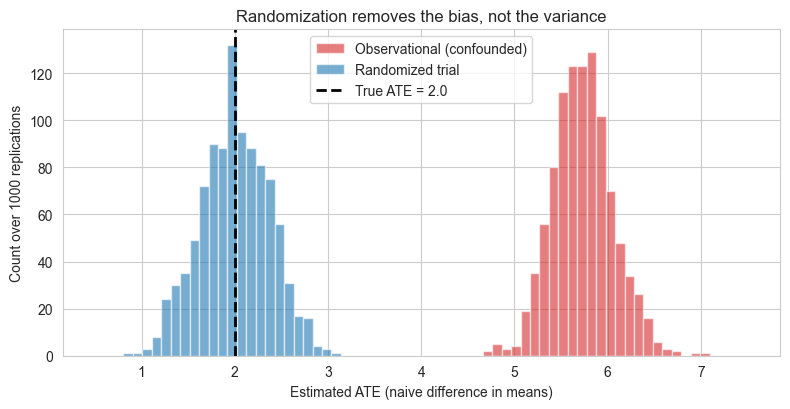

In [6]:
# 図: ランダム化の効果
fig, ax = plt.subplots(figsize=(8, 4.2))
bins = np.linspace(0.5, 7.5, 70)
ax.hist(trial_results['観察研究（交絡あり）'], bins=bins, alpha=0.6,
        color='tab:red', label='Observational (confounded)')
ax.hist(trial_results['ランダム化比較試験'], bins=bins, alpha=0.6,
        color='tab:blue', label='Randomized trial')
ax.axvline(TRUE_ATE, color='k', ls='--', lw=2, label=f'True ATE = {TRUE_ATE}')
ax.set_xlabel('Estimated ATE (naive difference in means)')
ax.set_ylabel('Count over 1000 replications')
ax.set_title('Randomization removes the bias, not the variance')
ax.legend()
plt.tight_layout()
plt.show()

### 読み取れること

| 設定 | 推定の平均 | バイアス | 標準偏差 |
|---|---|---|---|
| 観察研究（交絡あり） | +5.7320 | **+3.7320** | 0.3264 |
| ランダム化比較試験 | +2.0005 | **+0.0005** | 0.3690 |

**ランダム化はバイアスを消しますが、分散は消しません。** むしろ標準偏差は
わずかに大きくなっています（0.3690 対 0.3264）。交絡のある割り当ては
偶然偏りが小さく見えることがあるので、ばらつきが小さいことは正しさを意味しません。

重要なのは**バイアスは標本を増やしても消えない**ことです。
観察研究の +3.73 は系統誤差なので、$n$ を 10 倍にしても 100 倍にしても残ります。
「サンプルを増やせば正確になる」は偶然誤差にだけ当てはまります。

## 33.4 交絡の統制 — 4つの方法と、それぞれがずれる理由

ランダム化できない場合、無交絡の仮定の下で**観測された交絡因子を統制**します。
代表的な4つを、真の ATE が分かる設定で比較します。

$$X_1, X_2 \sim \mathcal{N}(0,1), \quad
P(T=1\mid X) = \sigma(1.2X_1 - 0.8X_2), \quad
Y = \underbrace{2.0}_{\text{真の ATE}}\cdot T + 3X_1 - 2X_2 + \varepsilon$$

| 方法 | 考え方 |
|---|---|
| **回帰調整** | $Y$ を $T$ と $X$ に回帰し、$T$ の係数を効果とみなす |
| **傾向スコア IPW** | 傾向スコア $e(X)=P(T=1\mid X)$ の逆数で重み付けして疑似的なランダム化を作る |
| **傾向スコア層別化** | 傾向スコアの分位でグループを作り、各グループ内で比較して重み付け平均 |
| **傾向スコアマッチング** | 傾向スコアが近い処置個体と対照個体を対にして比較 |

**本節の主題は「どれが一番良いか」ではなく「それぞれがどう失敗するか」です。**

In [7]:
# 真の ATE が分かる交絡のある設定
TRUE_ATE = 2.0

def make_confounded(n=4000, seed=7):
    rng = np.random.default_rng(seed)
    X1 = rng.normal(0, 1, n)
    X2 = rng.normal(0, 1, n)
    T = (rng.random(n) < 1 / (1 + np.exp(-(1.2 * X1 - 0.8 * X2)))).astype(int)
    Y = TRUE_ATE * T + 3 * X1 - 2 * X2 + rng.normal(0, 1, n)
    return np.c_[X1, X2], T, Y


X, T, Y = make_confounded()
ps = LogisticRegression(max_iter=1000).fit(X, T).predict_proba(X)[:, 1]

print(f"真の ATE = {TRUE_ATE}   処置群 {T.sum()}人 / 対照群 {(1-T).sum()}人")
print(f"傾向スコアの範囲: [{ps.min():.4f}, {ps.max():.4f}]")
print(f"  -> 0 と 1 を含まないので正値性は満たされているが、端が極端（IPW の重みが膨らむ）")
print()

results = {}
naive = Y[T == 1].mean() - Y[T == 0].mean()
results['素朴な平均の差'] = naive

# (a) 回帰調整（正しい定式化）
res = sm.OLS(Y, sm.add_constant(np.c_[T, X])).fit()
results['回帰調整（正しい定式化）'] = res.params[1]
# (b) 回帰調整（交絡因子 X2 を落とす = 定式化の誤り）
res_mis = sm.OLS(Y, sm.add_constant(np.c_[T, X[:, 0]])).fit()
results['回帰調整（X2 を落とす）'] = res_mis.params[1]
# (c) IPW
w = np.where(T == 1, 1 / ps, 1 / (1 - ps))
results['IPW'] = ((w * T * Y).sum() / (w * T).sum()
                  - (w * (1 - T) * Y).sum() / (w * (1 - T)).sum())

print(f"{'方法':<28}{'推定値':>10}{'誤差':>10}")
print("-" * 50)
for k, v in results.items():
    print(f"{k:<28}{v:>+10.4f}{v-TRUE_ATE:>+10.4f}")
print("-" * 50)
print(f"IPW の最大の重み: {w.max():.1f}   <- 傾向スコアが {ps.min():.4f} の個体で 1/{ps.min():.4f}")

真の ATE = 2.0   処置群 1971人 / 対照群 2029人
傾向スコアの範囲: [0.0028, 0.9921]
  -> 0 と 1 を含まないので正値性は満たされているが、端が極端（IPW の重みが膨らむ）

方法                                 推定値        誤差
--------------------------------------------------
素朴な平均の差                        +5.6691   +3.6691
回帰調整（正しい定式化）                   +2.0510   +0.0510
回帰調整（X2 を落とす）                  +3.3868   +1.3868
IPW                            +2.1950   +0.1950
--------------------------------------------------
IPW の最大の重み: 39.9   <- 傾向スコアが 0.0028 の個体で 1/0.0028


In [8]:
# IPW をトリミングして重みを抑える
print("IPW のトリミング（極端な傾向スコアの個体を除く）")
print(f"{'範囲':<24}{'推定値':>10}{'誤差':>10}{'残った人数':>12}{'最大の重み':>12}")
print("-" * 70)
ipw_rows = [('トリミングなし', 0.0, 1.0)]
for lo, hi in [(0.05, 0.95), (0.1, 0.9)]:
    ipw_rows.append((f'{lo} < ps < {hi}', lo, hi))
ipw_results = []
for tag, lo, hi in ipw_rows:
    m = (ps > lo) & (ps < hi)
    wt = np.where(T[m] == 1, 1 / ps[m], 1 / (1 - ps[m]))
    e = ((wt * T[m] * Y[m]).sum() / (wt * T[m]).sum()
         - (wt * (1 - T[m]) * Y[m]).sum() / (wt * (1 - T[m])).sum())
    ipw_results.append((tag, e, m.sum(), wt.max()))
    print(f"{tag:<24}{e:>+10.4f}{e-TRUE_ATE:>+10.4f}{m.sum():>12}{wt.max():>12.1f}")
print("-" * 70)
print("-> 重みが小さくなるほど誤差も小さくなる。極端な重みが分散とバイアスの両方を悪化させる。")
print("   ただしトリミングは推定対象を変える（除いた人は結論の対象外になる）。")
print()

# 傾向スコア層別化: 分位数の数を振る
print("傾向スコア層別化（分位数の数を振る）")
print(f"{'分位数':<12}{'推定値':>10}{'誤差':>10}")
print("-" * 34)
strat_results = []
for k in [5, 10, 20, 50]:
    qs = np.quantile(ps, np.linspace(0, 1, k + 1))
    bins = np.digitize(ps, qs[1:-1])
    est, tot = 0.0, 0
    for b in np.unique(bins):
        m = bins == b
        if (T[m] == 1).sum() > 0 and (T[m] == 0).sum() > 0:
            est += m.sum() * (Y[m & (T == 1)].mean() - Y[m & (T == 0)].mean())
            tot += m.sum()
    strat_results.append((k, est / tot))
    print(f"{k:<12}{est/tot:>+10.4f}{est/tot-TRUE_ATE:>+10.4f}")
print("-" * 34)
print("-> 分位数を増やすと層内の残留交絡が減り、誤差が単調に小さくなる。")

IPW のトリミング（極端な傾向スコアの個体を除く）
範囲                             推定値        誤差       残った人数       最大の重み
----------------------------------------------------------------------
トリミングなし                    +2.1950   +0.1950        4000        39.9
0.05 < ps < 0.95           +2.1309   +0.1309        3859        18.2
0.1 < ps < 0.9             +2.0830   +0.0830        3529         9.9
----------------------------------------------------------------------
-> 重みが小さくなるほど誤差も小さくなる。極端な重みが分散とバイアスの両方を悪化させる。
   ただしトリミングは推定対象を変える（除いた人は結論の対象外になる）。

傾向スコア層別化（分位数の数を振る）
分位数                推定値        誤差
----------------------------------
5              +2.5188   +0.5188
10             +2.2069   +0.2069
20             +2.1380   +0.1380
50             +2.1020   +0.1020
----------------------------------
-> 分位数を増やすと層内の残留交絡が減り、誤差が単調に小さくなる。


In [9]:
# 傾向スコアマッチング: 復元あり / なし
idx_t = np.where(T == 1)[0]
idx_c = np.where(T == 0)[0]

# 復元あり: 各処置個体に最も近い対照を、重複を許して割り当てる
j_near = idx_c[np.argmin(np.abs(ps[idx_c][None, :] - ps[idx_t][:, None]), axis=1)]
m_with = float(np.mean(Y[idx_t] - Y[j_near]))
n_uniq = len(np.unique(j_near))
d_with = np.abs(ps[idx_t] - ps[j_near])

# 復元なし: 傾向スコアの降順に貪欲に対にする
order = idx_t[np.argsort(-ps[idx_t])]
avail = set(idx_c.tolist())
pairs = []
for i in order:
    if not avail:
        break
    a = np.fromiter(avail, int)
    j = a[int(np.argmin(np.abs(ps[a] - ps[i])))]
    avail.discard(j)
    pairs.append((i, j))
m_wo = float(np.mean([Y[i] - Y[j] for i, j in pairs]))
d_wo = np.array([abs(ps[i] - ps[j]) for i, j in pairs])

print("傾向スコアマッチング")
print(f"{'方式':<20}{'推定値':>10}{'誤差':>10}{'使った対照':>14}{'|ps の差| 中央値':>18}")
print("-" * 74)
print(f"{'復元あり':<20}{m_with:>+10.4f}{m_with-TRUE_ATE:>+10.4f}"
      f"{f'{n_uniq}/{len(idx_c)}':>14}{np.median(d_with):>18.5f}")
print(f"{'復元なし':<20}{m_wo:>+10.4f}{m_wo-TRUE_ATE:>+10.4f}"
      f"{f'{len(pairs)}/{len(idx_c)}':>14}{np.median(d_wo):>18.5f}")
print("-" * 74)
print(f"素朴な平均の差（参考）: {naive:+.4f}")
print()
print("復元なしが素朴な差とほぼ同じになった理由:")
print(f"  処置群 {len(idx_t)}人 vs 対照群 {len(idx_c)}人 でサイズが近いため、")
print(f"  復元なしでは対照群のほぼ全員（{len(pairs)}/{len(idx_c)}）を使わざるを得ない。")
print("  マッチ後の対照群が元の対照群とほぼ同じになり、統制の効果が消える。")
print(f"  マッチの質も 1000 倍以上悪い（|ps の差| の中央値 "
      f"{np.median(d_with):.5f} 対 {np.median(d_wo):.5f}）。")

傾向スコアマッチング
方式                         推定値        誤差         使った対照       |ps の差| 中央値
--------------------------------------------------------------------------
復元あり                   +2.1590   +0.1590      793/2029           0.00026
復元なし                   +5.4489   +3.4489     1971/2029           0.28378
--------------------------------------------------------------------------
素朴な平均の差（参考）: +5.6691

復元なしが素朴な差とほぼ同じになった理由:
  処置群 1971人 vs 対照群 2029人 でサイズが近いため、
  復元なしでは対照群のほぼ全員（1971/2029）を使わざるを得ない。
  マッチ後の対照群が元の対照群とほぼ同じになり、統制の効果が消える。
  マッチの質も 1000 倍以上悪い（|ps の差| の中央値 0.00026 対 0.28378）。


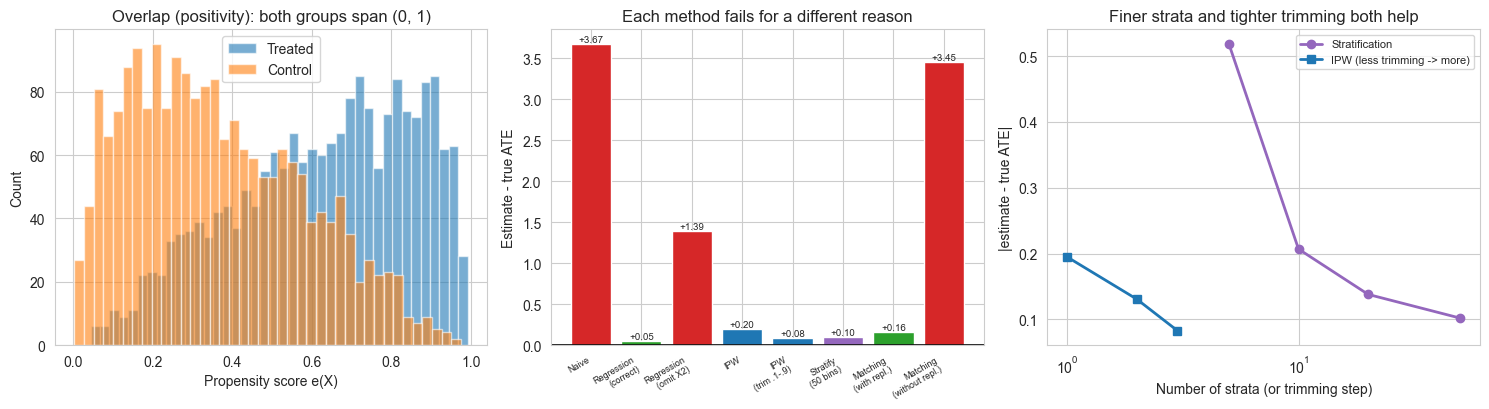

In [10]:
# 図: 傾向スコアの重なりと各手法の誤差
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].hist(ps[T == 1], bins=40, alpha=0.6, color='tab:blue', label='Treated')
axes[0].hist(ps[T == 0], bins=40, alpha=0.6, color='tab:orange', label='Control')
axes[0].set_xlabel('Propensity score e(X)')
axes[0].set_ylabel('Count')
axes[0].set_title('Overlap (positivity): both groups span (0, 1)')
axes[0].legend()

methods = ['Naive', 'Regression\n(correct)', 'Regression\n(omit X2)', 'IPW',
           'IPW\n(trim .1-.9)', 'Stratify\n(50 bins)', 'Matching\n(with repl.)',
           'Matching\n(without repl.)']
errs = [naive - TRUE_ATE,
        results['回帰調整（正しい定式化）'] - TRUE_ATE,
        results['回帰調整（X2 を落とす）'] - TRUE_ATE,
        results['IPW'] - TRUE_ATE,
        ipw_results[-1][1] - TRUE_ATE,
        strat_results[-1][1] - TRUE_ATE,
        m_with - TRUE_ATE,
        m_wo - TRUE_ATE]
colors = ['tab:red', 'tab:green', 'tab:red', 'tab:blue', 'tab:blue',
          'tab:purple', 'tab:green', 'tab:red']
axes[1].bar(range(len(methods)), errs, color=colors)
axes[1].axhline(0, color='k', lw=1.2)
axes[1].set_xticks(range(len(methods)))
axes[1].set_xticklabels(methods, fontsize=6.5, rotation=30, ha='right')
axes[1].set_ylabel('Estimate - true ATE')
axes[1].set_title('Each method fails for a different reason')
for i, v in enumerate(errs):
    axes[1].text(i, v, f"{v:+.2f}", ha='center',
                 va='bottom' if v >= 0 else 'top', fontsize=7)

axes[2].plot([r[0] for r in strat_results],
             [abs(r[1] - TRUE_ATE) for r in strat_results],
             'o-', lw=2, color='tab:purple', label='Stratification')
axes[2].plot([1, 2, 3], [abs(r[1] - TRUE_ATE) for r in ipw_results],
             's-', lw=2, color='tab:blue', label='IPW (less trimming -> more)')
axes[2].set_xscale('log')
axes[2].set_xlabel('Number of strata (or trimming step)')
axes[2].set_ylabel('|estimate - true ATE|')
axes[2].set_title('Finer strata and tighter trimming both help')
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 読み取れること — 4つの方法はそれぞれ違う理由でずれる

| 方法 | 推定値 | 誤差 | ずれる理由 |
|---|---|---|---|
| 素朴な平均の差 | +5.6691 | **+3.6691** | 交絡を全く統制していない |
| **回帰調整（正しい定式化）** | **+2.0510** | **+0.0510** | — |
| 回帰調整（$X_2$ を落とす） | +3.3868 | **+1.3868** | **定式化の誤り**。落とした交絡因子の影響が残る |
| IPW（トリミングなし） | +2.1950 | +0.1950 | **極端な重み**（最大 39.9）が分散とバイアスを悪化 |
| IPW（$0.1 < e < 0.9$） | +2.0830 | +0.0830 | トリミングで改善。ただし推定対象が変わる |
| 層別化（5分位） | +2.5188 | +0.5188 | **層内の残留交絡** |
| 層別化（50分位） | +2.1020 | +0.1020 | 層を細かくすると改善 |
| マッチング（復元あり） | +2.1590 | +0.1590 | — |
| マッチング（復元なし） | +5.4489 | **+3.4489** | **対照群をほぼ全員使うので統制にならない** |

4つの失敗の仕方を整理します。

**1. 回帰調整は定式化に依存します。** $X_2$ を落とすと誤差が 0.051 から 1.387 に
27 倍悪化しました。「共変量を入れた回帰だから大丈夫」は成り立ちません。
交絡因子を**漏れなく**、かつ**正しい関数形で**入れる必要があります。

**2. IPW は極端な傾向スコアに弱いです。** 最小の傾向スコアが 0.0028 の個体の重みは
1/0.0028 ≈ 357 になり、その1人が推定値を左右します。実測では最大の重みが 39.9 で、
トリミングで 9.9 まで下げると誤差が 0.195 → 0.083 に改善しました。
**正値性が「満たされている」だけでは不十分で、端がどれだけ極端かが効きます。**

**3. 層別化は層の粗さがそのまま残留交絡になります。** 5分位（誤差 0.519）から
50分位（0.102）へ単調に改善しました。層内では交絡を無視しているので、
層が粗いほど無視する量が大きくなります。

**4. マッチングは群のサイズ比に強く依存します。** これが本節で最も見落とされやすい点です。
処置群 1971 人・対照群 2029 人でサイズが近いため、**1対1の復元なしマッチングでは
対照群の 1971/2029 人を使わざるを得ません**。マッチ後の対照群が元の対照群とほぼ同じなので、
統制の効果が消えて素朴な差（+5.67）とほぼ同じ値（+5.45）になりました。

マッチの質を見ると原因が確定します。傾向スコアの差の中央値は
**復元あり 0.00026 / 復元なし 0.28378 で 1000 倍以上**違います。
復元ありは対照群の 793/2029 人だけを使い、残りを捨てることで質を確保しています。

> ⚠️ **「マッチングした」は「交絡を統制した」を意味しません。**
> マッチの質（共変量バランス・傾向スコアの差）を必ず報告してください。
> 対照群のプールが処置群より十分大きくないと、復元なしマッチングは機能しません。

## 33.5 調整してはいけない変数 — 合流点と中間変数

33.4 は「交絡因子を調整する」話でした。しかし**調整すると悪化する変数**があります。
どの変数を調整すべきかは、データからは決まりません。
**因果の構造（どれが原因でどれが結果か）**から決まります。

| 変数の種類 | 構造 | 調整すべきか |
|---|---|---|
| **交絡因子** | $X \to T$ かつ $X \to Y$ | **調整する**（しないとバイアス） |
| **合流点（collider）** | $T \to C$ かつ $Y \to C$ | **調整しない**（するとバイアスが生まれる） |
| **中間変数（mediator）** | $T \to M \to Y$ | **総効果を知りたいなら調整しない** |

### 合流点を調整すると、何もないところにバイアスが生まれる

$T$ と $Y$ が**完全に独立**（真の因果効果 0）な状況を作り、
両方から影響を受ける変数 $C = T + Y + \varepsilon$ を調整してみます。

In [11]:
# 合流点バイアス: 真の因果効果が 0 の設定
def make_collider(n=5000, seed=3):
    rng = np.random.default_rng(seed)
    T = rng.normal(0, 1, n)          # T と Y は独立（真の効果は 0）
    Y = rng.normal(0, 1, n)
    C = T + Y + rng.normal(0, 0.5, n)   # 合流点: T と Y の両方から影響を受ける
    return T, Y, C


T2, Y2, C2 = make_collider()
r0 = np.corrcoef(T2, Y2)[0, 1]
res_none = sm.OLS(Y2, sm.add_constant(T2)).fit()
res_coll = sm.OLS(Y2, sm.add_constant(np.c_[T2, C2])).fit()

print("設定: T と Y は独立（真の因果効果 = 0）。C = T + Y + noise は合流点")
print()
print(f"T と Y の相関                   : {r0:+.4f}")
print(f"調整しない回帰の T の係数         : {res_none.params[1]:+.4f}  "
      f"(SE {res_none.bse[1]:.4f})  <- 正しい（ほぼ 0）")
print(f"合流点 C を調整した T の係数      : {res_coll.params[1]:+.4f}  "
      f"(SE {res_coll.bse[1]:.4f})  <- バイアスが作られた")
print()
print("注目すべき点: 合流点を調整すると標準誤差が小さくなっている")
print(f"  {res_none.bse[1]:.4f} -> {res_coll.bse[1]:.4f}（{res_none.bse[1]/res_coll.bse[1]:.1f} 分の1）")
print("  つまり『より精密に、より間違った』推定になる。")
print("  決定係数も上がる: R^2 "
      f"{res_none.rsquared:.4f} -> {res_coll.rsquared:.4f}")
print("  -> 当てはまりの良さは、因果効果の正しさの証拠にならない。")

設定: T と Y は独立（真の因果効果 = 0）。C = T + Y + noise は合流点

T と Y の相関                   : +0.0146
調整しない回帰の T の係数         : +0.0145  (SE 0.0141)  <- 正しい（ほぼ 0）
合流点 C を調整した T の係数      : -0.7937  (SE 0.0083)  <- バイアスが作られた

注目すべき点: 合流点を調整すると標準誤差が小さくなっている
  0.0141 -> 0.0083（1.7 分の1）
  つまり『より精密に、より間違った』推定になる。
  決定係数も上がる: R^2 0.0002 -> 0.8071
  -> 当てはまりの良さは、因果効果の正しさの証拠にならない。


In [12]:
# 中間変数: 総効果と直接効果は別のもの
def make_mediator(n=5000, seed=4):
    rng = np.random.default_rng(seed)
    T = (rng.random(n) < 0.5).astype(float)
    M = 1.5 * T + rng.normal(0, 1, n)              # 中間変数
    Y = 1.0 * T + 2.0 * M + rng.normal(0, 1, n)    # 直接 1.0 + 間接 1.5*2.0 = 3.0
    return T, M, Y


T3, M3, Y3 = make_mediator()
tot = sm.OLS(Y3, sm.add_constant(T3)).fit().params[1]
dir_ = sm.OLS(Y3, sm.add_constant(np.c_[T3, M3])).fit().params[1]

print("設定: 直接効果 1.0 + 間接効果 (1.5 x 2.0) = 3.0  -> 総効果 4.0")
print()
print(f"調整しない回帰の T の係数       : {tot:+.4f}  <- 総効果（4.0）の推定として正しい")
print(f"中間変数 M を調整した T の係数   : {dir_:+.4f}  <- 直接効果（1.0）になる")
print()
print("どちらも「間違い」ではなく、推定している対象が違う。")
print("  『処置を導入したら結果はどう変わるか』を知りたい -> 総効果 -> M を調整しない")
print("  『M を経由しない経路の効果』を知りたい           -> 直接効果 -> M を調整する")
print("-> 何を推定したいのかを決める前に、調整する変数は決められない。")

設定: 直接効果 1.0 + 間接効果 (1.5 x 2.0) = 3.0  -> 総効果 4.0

調整しない回帰の T の係数       : +4.0538  <- 総効果（4.0）の推定として正しい
中間変数 M を調整した T の係数   : +1.0409  <- 直接効果（1.0）になる

どちらも「間違い」ではなく、推定している対象が違う。
  『処置を導入したら結果はどう変わるか』を知りたい -> 総効果 -> M を調整しない
  『M を経由しない経路の効果』を知りたい           -> 直接効果 -> M を調整する
-> 何を推定したいのかを決める前に、調整する変数は決められない。


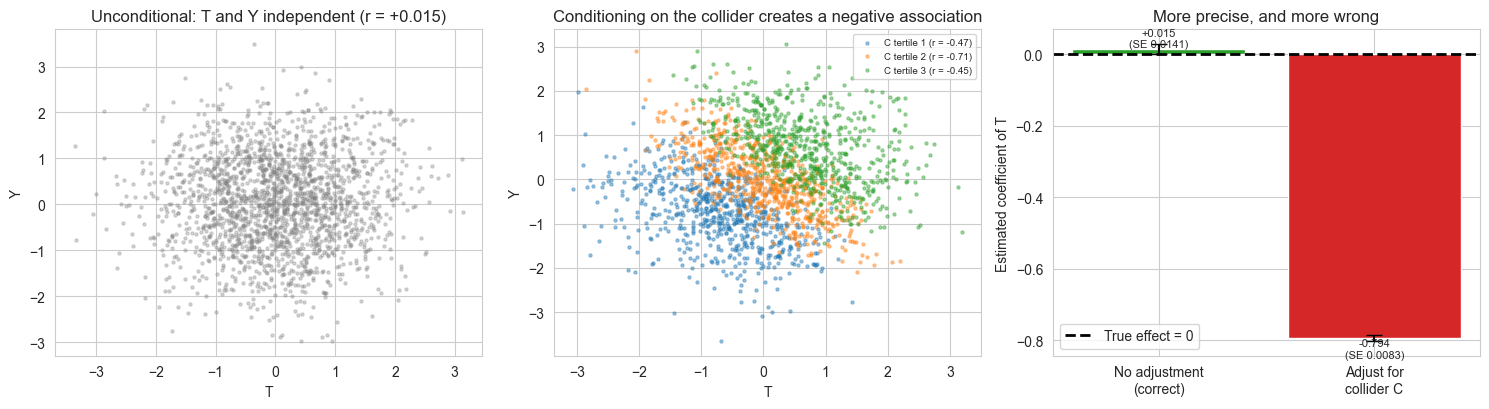

In [13]:
# 図: 合流点バイアスの仕組み
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

sub = np.random.default_rng(0).choice(len(T2), 2000, replace=False)
axes[0].scatter(T2[sub], Y2[sub], s=5, alpha=0.3, color='tab:gray')
axes[0].set_xlabel('T')
axes[0].set_ylabel('Y')
axes[0].set_title(f'Unconditional: T and Y independent (r = {r0:+.3f})')

# C で層別すると負の関連が現れる
qs = np.quantile(C2, [0, 1/3, 2/3, 1.0])
bins = np.digitize(C2, qs[1:-1])
cols = ['tab:blue', 'tab:orange', 'tab:green']
for b in range(3):
    m = bins == b
    s = np.random.default_rng(b).choice(np.where(m)[0], min(700, m.sum()), replace=False)
    axes[1].scatter(T2[s], Y2[s], s=5, alpha=0.4, color=cols[b],
                    label=f'C tertile {b+1} (r = {np.corrcoef(T2[m], Y2[m])[0,1]:+.2f})')
axes[1].set_xlabel('T')
axes[1].set_ylabel('Y')
axes[1].set_title('Conditioning on the collider creates a negative association')
axes[1].legend(fontsize=7)

names = ['No adjustment\n(correct)', 'Adjust for\ncollider C']
vals = [res_none.params[1], res_coll.params[1]]
ses = [res_none.bse[1], res_coll.bse[1]]
axes[2].bar(names, vals, yerr=ses, capsize=6, color=['tab:green', 'tab:red'])
axes[2].axhline(0, color='k', ls='--', lw=2, label='True effect = 0')
axes[2].set_ylabel('Estimated coefficient of T')
axes[2].set_title('More precise, and more wrong')
axes[2].legend()
for i, (v, s) in enumerate(zip(vals, ses)):
    axes[2].text(i, v, f"{v:+.3f}\n(SE {s:.4f})", ha='center',
                 va='bottom' if v >= 0 else 'top', fontsize=8)

plt.tight_layout()
plt.show()

### 読み取れること — 調整は「増やせば良い」ものではない

**合流点の調整**（真の因果効果は 0）:

| | 係数 | 標準誤差 | $R^2$ |
|---|---|---|---|
| 調整しない | **+0.0145** | 0.0141 | 0.0002 |
| 合流点 $C$ を調整 | **-0.7937** | **0.0083** | **0.8071** |

真の効果が 0 なのに **-0.79** という大きな負の効果が現れました。
**何もないところからバイアスが作られています。**

さらに重要なのは、**標準誤差が 1.7 分の1に小さくなり、$R^2$ が 0.0002 から 0.8071 へ
4000 倍上がっている**ことです。つまり「より精密に、より当てはまり良く、
より間違った」推定になります。

> ⚠️ **当てはまりの良さ（$R^2$・$p$ 値・標準誤差）は、因果効果の正しさの証拠になりません。**
> 合流点を入れると全部が改善して見えます。
> 変数を入れるかどうかは**統計量ではなく因果の構造**で決めてください。

中央の図が仕組みを示しています。$C$ を固定すると $T + Y \approx$ 一定になるので、
$T$ が大きい個体は $Y$ が小さくなければなりません。
**条件付けることで人工的な負の関連が生まれます。**

**中間変数の調整**（直接効果 1.0 + 間接効果 3.0 = 総効果 4.0）:

| | 係数 | 推定しているもの |
|---|---|---|
| 調整しない | **+4.0538** | 総効果（正しく 4.0） |
| 中間変数 $M$ を調整 | **+1.0409** | 直接効果（正しく 1.0） |

こちらは**どちらも間違いではありません**。推定対象が違うだけです。
「処置を導入したら結果はどう変わるか」を知りたいなら総効果なので $M$ を調整しません。

**何を推定したいのかを決める前に、調整する変数は決められません。**

## 33.6 自然実験のデザイン — DID・IV・RDD

無交絡の仮定が疑わしいとき、**観測されない交絡があっても識別できる**デザインがあります。
3つを、真の効果が分かる設定で測ります。

| デザイン | 識別の仮定 | 仮定が破れると |
|---|---|---|
| **差分の差分法（DID）** | **平行トレンド**（処置がなければ両群は同じ変化をした） | バイアスが残る |
| **操作変数法（IV）** | $Z$ は $T$ に影響し、$Y$ には $T$ 経由でのみ影響する（除外制約） | 弱い操作変数で分散が爆発 |
| **回帰不連続デザイン（RDD）** | カットオフ近傍で他の要因が連続 | 帯幅によるバイアスと分散のトレードオフ |

In [14]:
# 差分の差分法（DID）
TRUE_DID = 3.0

def make_did(n=2000, parallel=True, seed=11):
    rng = np.random.default_rng(seed)
    g = (rng.random(n) < 0.5).astype(int)            # 1 = 処置群
    a0 = rng.normal(0, 1, n)                          # 個体の固定効果
    y0 = 5 + 3 * g + a0 + rng.normal(0, 1, n)         # 期間 0（処置群は水準が +3 高い）
    trend = 2.0 if parallel else (2.0 + 2.5 * g)      # 平行トレンドの成立 / 破れ
    y1 = 5 + 3 * g + a0 + trend + TRUE_DID * g + rng.normal(0, 1, n)
    return g, y0, y1


print(f"真の処置効果 = {TRUE_DID}（処置群の水準が元から +3 高い = 選択バイアス）")
print()
did_rows = []
for tag, par in [('平行トレンドが成立', True), ('平行トレンドが破れている', False)]:
    g, y0, y1 = make_did(parallel=par)
    d_t = y1[g == 1].mean() - y0[g == 1].mean()
    d_c = y1[g == 0].mean() - y0[g == 0].mean()
    did = d_t - d_c
    cross = y1[g == 1].mean() - y1[g == 0].mean()
    did_rows.append((tag, cross, d_t, d_c, did))
    print(f"{tag}:")
    print(f"  期間1の群間差（素朴）    : {cross:+.4f}   誤差 {cross-TRUE_DID:+.4f}（水準差 3 が混入）")
    print(f"  処置群の前後差 {d_t:+.4f} / 対照群の前後差 {d_c:+.4f}")
    print(f"  DID = 前後差の差         : {did:+.4f}   誤差 {did-TRUE_DID:+.4f}")
    print()
print("DID は『水準の差』を前後差で消すが、『変化の差』は消せない。")
print("平行トレンドは検証できない仮定（処置がなかった場合の処置群の変化は観測できない）。")

真の処置効果 = 3.0（処置群の水準が元から +3 高い = 選択バイアス）

平行トレンドが成立:
  期間1の群間差（素朴）    : +5.9383   誤差 +2.9383（水準差 3 が混入）
  処置群の前後差 +4.9607 / 対照群の前後差 +1.9824
  DID = 前後差の差         : +2.9783   誤差 -0.0217

平行トレンドが破れている:
  期間1の群間差（素朴）    : +8.4383   誤差 +5.4383（水準差 3 が混入）
  処置群の前後差 +7.4607 / 対照群の前後差 +1.9824
  DID = 前後差の差         : +5.4783   誤差 +2.4783

DID は『水準の差』を前後差で消すが、『変化の差』は消せない。
平行トレンドは検証できない仮定（処置がなかった場合の処置群の変化は観測できない）。


In [15]:
# 操作変数法（2SLS）
TRUE_IV = 1.5

def make_iv(n=4000, z_strength=1.0, seed=5):
    rng = np.random.default_rng(seed)
    U = rng.normal(0, 1, n)                          # 観測されない交絡
    Z = rng.normal(0, 1, n)                          # 操作変数
    T = z_strength * Z + 1.5 * U + rng.normal(0, 1, n)
    Y = TRUE_IV * T + 2.0 * U + rng.normal(0, 1, n)
    return Z, T, Y


print(f"真の効果 = {TRUE_IV}（観測されない交絡 U が T と Y の両方に影響）")
print()
print(f"{'Z の強さ':<10}{'OLS':>10}{'誤差':>10}{'2SLS':>10}{'誤差':>10}{'第1段階 F':>12}")
print("-" * 62)
iv_rows = []
for zs in [1.0, 0.3, 0.05]:
    Z, T, Y = make_iv(z_strength=zs)
    ols = sm.OLS(Y, sm.add_constant(T)).fit()
    first = sm.OLS(T, sm.add_constant(Z)).fit()
    second = sm.OLS(Y, sm.add_constant(first.fittedvalues)).fit()
    F = first.tvalues[1] ** 2
    iv_rows.append((zs, ols.params[1], second.params[1], F))
    print(f"{zs:<10.2f}{ols.params[1]:>+10.4f}{ols.params[1]-TRUE_IV:>+10.4f}"
          f"{second.params[1]:>+10.4f}{second.params[1]-TRUE_IV:>+10.4f}{F:>12.1f}")
print("-" * 62)
print("第1段階の F < 10 は『弱い操作変数』の目安。")
print()

# 弱い操作変数で反復して分布を見る
print("2SLS 推定量の分布（300回の反復、n=1000）")
print(f"{'Z の強さ':<10}{'平均':>12}{'中央値':>12}{'標準偏差':>14}")
print("-" * 50)
iv_dist = {}
for zs in [1.0, 0.1]:
    es = []
    for s in range(300):
        Z, T, Y = make_iv(n=1000, z_strength=zs, seed=s)
        f = sm.OLS(T, sm.add_constant(Z)).fit()
        es.append(sm.OLS(Y, sm.add_constant(f.fittedvalues)).fit().params[1])
    es = np.array(es)
    iv_dist[zs] = es
    print(f"{zs:<10.2f}{es.mean():>+12.4f}{np.median(es):>+12.4f}{es.std():>14.4f}")
print("-" * 50)
print("弱い操作変数では標準偏差が 200 倍以上に膨らみ、平均が真値から大きく外れる。")
print("一方で中央値は真値に近い -> 推定量が重い裾を持ち、平均が代表値にならない。")

真の効果 = 1.5（観測されない交絡 U が T と Y の両方に影響）

Z の強さ            OLS        誤差      2SLS        誤差      第1段階 F
--------------------------------------------------------------
1.00         +2.1835   +0.6835   +1.4748   -0.0252      1281.1
0.30         +2.3829   +0.8829   +1.4156   -0.0844       114.2
0.05         +2.4095   +0.9095   +0.9760   -0.5240         3.0
--------------------------------------------------------------
第1段階の F < 10 は『弱い操作変数』の目安。

2SLS 推定量の分布（300回の反復、n=1000）
Z の強さ               平均         中央値          標準偏差
--------------------------------------------------
1.00           +1.4995     +1.5014        0.0664


0.10           +0.3891     +1.5694       14.3960
--------------------------------------------------
弱い操作変数では標準偏差が 200 倍以上に膨らみ、平均が真値から大きく外れる。
一方で中央値は真値に近い -> 推定量が重い裾を持ち、平均が代表値にならない。


In [16]:
# 回帰不連続デザイン（RDD）: 帯幅のバイアスと分散のトレードオフ
TRUE_RDD = 2.0

def make_rdd(n=4000, curv=0.0, seed=0):
    rng = np.random.default_rng(seed)
    x = rng.uniform(-1, 1, n)                  # 連続な割り当て変数（カットオフは 0）
    T = (x >= 0).astype(float)
    # curv > 0 で真の関係に曲率が入る（局所線形回帰にとっての定式化バイアス源）
    Y = 1.0 + 2.5 * x + curv * np.abs(x) * x * 3.0 + TRUE_RDD * T + rng.normal(0, 0.5, n)
    return x, T, Y


print(f"真の不連続（カットオフでの跳び）= {TRUE_RDD}")
x, T, Y = make_rdd(seed=9)
naive_rdd = Y[T == 1].mean() - Y[T == 0].mean()
print(f"素朴な群間差（全データ）: {naive_rdd:+.4f}   誤差 {naive_rdd-TRUE_RDD:+.4f}"
      f"（x の傾きが混入）")
print()

rdd_rows = {}
for curv, tag in [(0.0, '真の関係が線形'), (1.0, '真の関係に曲率がある')]:
    print(f"{tag}（200回の反復）")
    print(f"{'帯幅':>8}{'推定の平均':>12}{'バイアス':>11}{'標準偏差':>12}{'平均の人数':>12}")
    print("-" * 56)
    rows = []
    for bw in [1.0, 0.5, 0.2, 0.1]:
        ests, ns = [], []
        for s in range(200):
            x, T, Y = make_rdd(curv=curv, seed=s)
            m = np.abs(x) < bw
            r = sm.OLS(Y[m], sm.add_constant(np.c_[T[m], x[m]])).fit()
            ests.append(r.params[1])
            ns.append(m.sum())
        ests = np.array(ests)
        rows.append((bw, ests.mean(), ests.std(), np.mean(ns)))
        print(f"{bw:>8.2f}{ests.mean():>12.4f}{ests.mean()-TRUE_RDD:>+11.4f}"
              f"{ests.std():>12.4f}{np.mean(ns):>12.0f}")
    print("-" * 56)
    rdd_rows[curv] = rows
    print()
print("線形なら狭めても減らすバイアスが無く、分散だけ増える。")
print("曲率があると広い帯幅で定式化バイアスが出るので、狭めるとバイアスが減り分散が増える。")
print("-> 『帯幅を狭めるとバイアスが減る』は真の関係に曲率がある場合の話。")

真の不連続（カットオフでの跳び）= 2.0
素朴な群間差（全データ）: +4.4323   誤差 +2.4323（x の傾きが混入）

真の関係が線形（200回の反復）
      帯幅       推定の平均       バイアス        標準偏差       平均の人数
--------------------------------------------------------


    1.00      2.0020    +0.0020      0.0313        4000
    0.50      2.0023    +0.0023      0.0417        1996
    0.20      2.0019    +0.0019      0.0691         797


    0.10      2.0053    +0.0053      0.1094         400
--------------------------------------------------------

真の関係に曲率がある（200回の反復）
      帯幅       推定の平均       バイアス        標準偏差       平均の人数
--------------------------------------------------------


    1.00      1.0009    -0.9991      0.0343        4000
    0.50      1.7521    -0.2479      0.0419        1996
    0.20      1.9619    -0.0381      0.0691         797


    0.10      1.9953    -0.0047      0.1095         400
--------------------------------------------------------

線形なら狭めても減らすバイアスが無く、分散だけ増える。
曲率があると広い帯幅で定式化バイアスが出るので、狭めるとバイアスが減り分散が増える。
-> 『帯幅を狭めるとバイアスが減る』は真の関係に曲率がある場合の話。


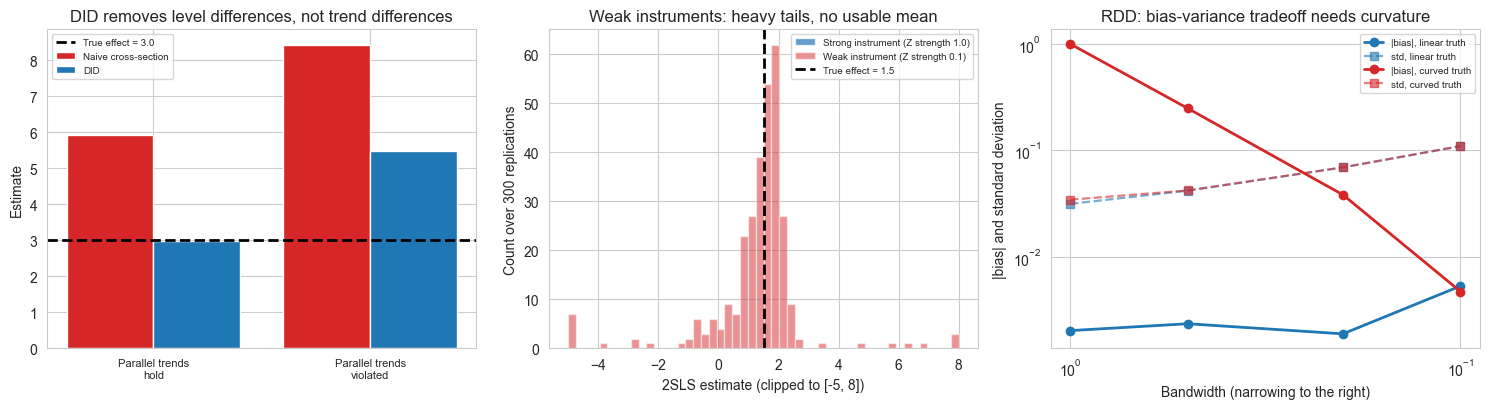

In [17]:
# 図: DID・IV・RDD
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# DID
labels = ['Parallel trends\nhold', 'Parallel trends\nviolated']
cross = [did_rows[0][1], did_rows[1][1]]
dids = [did_rows[0][4], did_rows[1][4]]
xp = np.arange(2)
axes[0].bar(xp - 0.2, cross, 0.4, label='Naive cross-section', color='tab:red')
axes[0].bar(xp + 0.2, dids, 0.4, label='DID', color='tab:blue')
axes[0].axhline(TRUE_DID, color='k', ls='--', lw=2, label=f'True effect = {TRUE_DID}')
axes[0].set_xticks(xp)
axes[0].set_xticklabels(labels, fontsize=8)
axes[0].set_ylabel('Estimate')
axes[0].set_title('DID removes level differences, not trend differences')
axes[0].legend(fontsize=7)

# IV: 弱い操作変数の分布
axes[1].hist(np.clip(iv_dist[1.0], -5, 8), bins=50, alpha=0.7, color='tab:blue',
             label='Strong instrument (Z strength 1.0)')
axes[1].hist(np.clip(iv_dist[0.1], -5, 8), bins=50, alpha=0.5, color='tab:red',
             label='Weak instrument (Z strength 0.1)')
axes[1].axvline(TRUE_IV, color='k', ls='--', lw=2, label=f'True effect = {TRUE_IV}')
axes[1].set_xlabel('2SLS estimate (clipped to [-5, 8])')
axes[1].set_ylabel('Count over 300 replications')
axes[1].set_title('Weak instruments: heavy tails, no usable mean')
axes[1].legend(fontsize=7)

# RDD: バイアスと分散のトレードオフ
for curv, color, tag in [(0.0, 'tab:blue', 'linear truth'),
                         (1.0, 'tab:red', 'curved truth')]:
    rows = rdd_rows[curv]
    axes[2].plot([r[0] for r in rows], [abs(r[1] - TRUE_RDD) for r in rows],
                 'o-', lw=2, color=color, label=f'|bias|, {tag}')
    axes[2].plot([r[0] for r in rows], [r[2] for r in rows],
                 's--', lw=1.6, color=color, alpha=0.6, label=f'std, {tag}')
axes[2].set_xscale('log')
axes[2].set_yscale('log')
axes[2].invert_xaxis()
axes[2].set_xlabel('Bandwidth (narrowing to the right)')
axes[2].set_ylabel('|bias| and standard deviation')
axes[2].set_title('RDD: bias-variance tradeoff needs curvature')
axes[2].legend(fontsize=7)

plt.tight_layout()
plt.show()

### 読み取れること

**差分の差分法（DID）** — 真の効果 3.0:

| 設定 | 期間1の群間差（素朴） | DID |
|---|---|---|
| 平行トレンドが成立 | +5.9383（誤差 +2.9383） | **+2.9783（誤差 -0.0217）** |
| 平行トレンドが破れている | +8.4383（誤差 +5.4383） | **+5.4783（誤差 +2.4783）** |

DID は**水準の差**（処置群が元から +3 高い）を前後差で消します。
しかし**変化の差**は消せません。平行トレンドが破れると誤差 2.48 が残ります。

**平行トレンドは検証できない仮定**です。「処置がなかった場合の処置群の変化」は
観測できないからです。処置前の複数期間でトレンドが平行かを見る（pre-trend test）のが
慣行ですが、それは仮定の検証ではなく**反証の試み**にすぎません。

**操作変数法（IV）** — 真の効果 1.5:

| $Z$ の強さ | OLS | 2SLS | 第1段階 $F$ |
|---|---|---|---|
| 1.00 | +2.1835（誤差 +0.68） | **+1.4748（誤差 -0.03）** | 1281.1 |
| 0.30 | +2.3829（誤差 +0.88） | +1.4156（誤差 -0.08） | 114.2 |
| 0.05 | +2.4095（誤差 +0.91） | **+0.9760（誤差 -0.52）** | **3.0** |

OLS は観測されない交絡のため一貫して +0.7〜0.9 のバイアスを持ちます。
2SLS は操作変数が強ければ真値を復元しますが、**弱いと壊れます**。

300回反復した分布がそれを示します。

| $Z$ の強さ | 平均 | 中央値 | 標準偏差 |
|---|---|---|---|
| 1.0 | +1.4995 | +1.5014 | **0.0664** |
| 0.1 | **+0.3891** | +1.5694 | **14.3960** |

**標準偏差が 217 倍**に膨らみ、**平均（+0.39）が真値から大きく外れる一方、
中央値（+1.57）は近い**です。弱い操作変数の 2SLS 推定量は
**裾が重く、平均が代表値になりません**（理論上はモーメントが存在しません）。
だから「平均的には正しい」という議論が成立しません。

**回帰不連続デザイン（RDD）** — 真の跳び 2.0、素朴な群間差は +4.4323（誤差 +2.43）:

| 帯幅 | 線形: バイアス | 線形: 標準偏差 | 曲率あり: バイアス | 曲率あり: 標準偏差 |
|---|---|---|---|---|
| 1.00 | +0.0020 | 0.0313 | **-0.9991** | 0.0343 |
| 0.50 | +0.0023 | 0.0417 | -0.2479 | 0.0419 |
| 0.20 | +0.0019 | 0.0691 | -0.0381 | 0.0691 |
| 0.10 | +0.0053 | **0.1094** | **-0.0047** | **0.1095** |

**この表は私の最初の見立てを修正しました。** 「帯幅を狭めるとバイアスが減り
分散が増える」と書くつもりでしたが、**真の関係が線形なら減らすバイアスが無く、
分散だけが 3.5 倍増えます**。

バイアスと分散のトレードオフが成立するのは**真の関係に曲率がある場合**です。
曲率を入れると、帯幅 1.0 でバイアス -0.9991（真値の 50%）が出て、
0.1 まで狭めると -0.0047（**200 分の1**）になります。その代償が標準偏差 3.2 倍です。

> 📌 **帯幅の選択は「真の関係がどれだけ曲がっているか」に依存します。**
> 線形なら広い帯幅のほうが有利です。曲率が分からない場合に狭い帯幅を選ぶのは
> 「バイアスを恐れて分散を払う」保守的な選択で、常に正しいわけではありません。

---

## ⚠️ よくある間違いと解決策

### 1. 「共変量を入れた回帰だから交絡は統制した」

本章の実測: 交絡因子 $X_2$ を落とした回帰調整は誤差 **1.3868**（正しい定式化は 0.0510）。
**27 倍**悪化しました。

**解決策**: 交絡因子を漏れなく、正しい関数形で入れる。
入れられない交絡が疑われるなら、33.6 のデザイン（DID・IV・RDD）に切り替える。

### 2. 「変数を増やすほど正確になる」

本章の実測: 真の効果 0 の設定で合流点を調整すると係数 **-0.7937**。
しかも標準誤差は 1.7 分の1、$R^2$ は 0.0002 → 0.8071 に改善しました。
**当てはまりの良さは因果効果の正しさの証拠になりません。**

**解決策**: 変数を入れるかどうかは統計量ではなく**因果の構造**で決める。
処置より後に決まる変数（合流点・中間変数）は原則として入れない。

### 3. 「マッチングしたから群は比較可能」

本章の実測: 処置群 1971 人・対照群 2029 人で1対1の復元なしマッチングを行うと、
推定値 **+5.4489**（素朴な差 +5.6691 とほぼ同じ）。
マッチの質は復元ありの **1000 倍以上**悪い（$\lvert$ps の差$\rvert$ の中央値 0.28378 対 0.00026）。

**解決策**: マッチの質（共変量バランス・傾向スコアの差）を必ず報告する。
対照群のプールが処置群より十分大きくないなら、復元ありか他の方法を使う。

### 4. 「正値性は満たしているから IPW でよい」

本章の実測: 傾向スコアの最小値 0.0028（0 ではないので正値性は満たす）。
しかし最大の重みが 39.9 になり、トリミングで 9.9 に下げると誤差が
0.1950 → 0.0830 に改善しました。

**解決策**: 傾向スコアの分布と重みの最大値を必ず見る。
トリミングは推定対象を変えるので、除いた集団を明示する。

### 5. 「n を増やせば正確になる」

本章の実測: 交絡のある観察研究のバイアスは +3.7320 で、これは**系統誤差**です。
1000回の反復で平均がきれいに +5.7320 に集まっており、標本を増やしても消えません。

**解決策**: バイアスと分散を区別する。$n$ が効くのは分散だけ。

### 6. 「弱い操作変数でも平均的には正しい」

本章の実測: $Z$ の強さ 0.1 の 2SLS は平均 **+0.3891**（真値 1.5）、
標準偏差 **14.3960**、中央値 +1.5694。
平均が真値から大きく外れています（理論上モーメントが存在しません）。

**解決策**: 第1段階の $F$ 統計量を報告する（$F < 10$ は警告）。
弱い場合は推定量の分布を直接見る（平均ではなく中央値や分位点）。

---

## 📝 理解度チェック

次の問いに自分の言葉で答えられるか確認してください。

1. **因果推論の根本問題**とは何か。シミュレーションではなぜそれを迂回できるのか。
2. **ATE と ATT** の違いを式で書き、本章の 33.2 でこの2つが違う値になった理由を述べよ。
3. 無交絡の仮定 $\{Y(1),Y(0)\} \perp T \mid X$ は、**ランダム化比較試験では何によって保証**されるか。
4. 回帰調整・IPW・層別化・マッチングの4つについて、本章で実測した**失敗の原因をそれぞれ1つ**挙げよ。
5. ある変数を調整すべきかどうかは、データから決まるか。決まらないなら何から決まるか。
6. 合流点を調整すると $R^2$ が上がり標準誤差が下がった。**この事実から何を学ぶべきか。**
7. 中間変数を調整した推定値は「間違い」か。そうでないなら何が違うのか。
8. DID が消せる差と消せない差は何か。**平行トレンドは検証できるか。**
9. 弱い操作変数のとき、2SLS 推定量の**平均を報告してはいけない理由**を述べよ。
10. RDD で帯幅を狭めることが有利になるのは、どういう条件のときか。
    本章の実測で、線形な設定では何が起きたか。

---

## 📚 まとめ

本章で測ったことを一覧にします。すべて**真の効果が分かる人工データ**での実測です。

| 節 | 測ったこと | 結果 |
|---|---|---|
| 33.1 | Simpson のパラドックス | 層ごと +0.1025 / +0.1029 なのに全体 **-0.1755**。層別化で +0.1027 に復元 |
| 33.2 | 潜在結果と ATE/ATT | ATE と ATT が違う値になる（効果の異質性 + 選択） |
| 33.3 | ランダム化の効果（1000回） | 観察研究のバイアス **+3.7320** / RCT **+0.0005**。分散はむしろ RCT が大きい |
| 33.4 | 4つの統制方法 | 回帰調整（正しい）+0.0510 が最良。定式化を誤ると +1.3868、復元なしマッチングは **+3.4489** |
| 33.5 | 合流点バイアス | 真の効果 0 に対して **-0.7937** のバイアスを作り出す。$R^2$ は 0.0002 → 0.8071 |
| 33.5 | 中間変数 | 総効果 +4.0538 / 直接効果 +1.0409。どちらも正しいが対象が違う |
| 33.6 | DID | 平行トレンド成立で誤差 -0.0217、破れると **+2.4783** |
| 33.6 | IV | 強い $Z$ で誤差 -0.03。弱い $Z$ で標準偏差が **217 倍**、平均が +0.3891（中央値は +1.5694） |
| 33.6 | RDD | 曲率があればバイアスが **200 分の1**に。線形なら分散だけ 3.5 倍増える |

### 本章の一貫した主張

**どの手法も、前提が合っているときだけ機能します。**
そして**前提が合っているかどうかは、多くの場合データからは分かりません。**

- 無交絡の仮定は検証できません（観測されない交絡は定義上観測できない）
- 平行トレンドは検証できません（処置がなかった場合の変化は観測できない）
- 除外制約は検証できません（$Z$ が $Y$ に直接影響しないことは示せない）

統計的因果推論は**仮定を明示し、その下で何が言えるかを述べる**技術です。
「データに語らせる」のではなく、**どの仮定を置いたかを読者に示す**のが作法です。

### 次に読むもの

| 章 | 関係 |
|---|---|
| 第16-19章（回帰分析） | 回帰調整の土台。定式化の誤りの影響は第17章（回帰診断）と直結 |
| 第18章（質的回帰） | 傾向スコアの推定にロジスティック回帰を使う |
| 第21章（標本調査法） | IPW の重み付けは標本調査の設計重みと同じ発想 |
| 第29章（不完全データ） | 欠測の統制は因果推論と同じ枠組みで扱える（欠測を「処置」とみなす） |
| 第31章（ベイズ法） | 感度分析（未観測交絡の大きさを仮定して結論の頑健性を調べる）に使う |

---